# 05 · Twenty more hypotheses (H4–H23)
**Exploratory analysis beyond the three pre-registered hypotheses**

> **At a glance:** 20 hypotheses in four themes → **10 supported, 3 partial, 7 rejected.**
> Rejections count: several of them are the most surprising findings.
>
> **Five to remember**
> * **H13** — after a state price cut, store orders jump **+49% the month *after*** the cut, not during it.
> * **H17 + H3** — ~**40–50%** of a new outlet's volume is new demand; two independent methods agree.
> * **H22** — when a shop changes owner it keeps **92%** of its volume: customers belong to the address.
> * **H20** — a new store's opening order is **1.86×** its normal level, then dips.
> * **H23** — "old counties drink Canadian whisky" is true but misleading: it is **rurality**, not age.

**Rules of the game**
* Each hypothesis states its **direction before** the test.
* County patterns are tested on Jan–Oct 2025 **and** Jan–Oct 2026 (same ten months), and count as supported only if
  they hold **in both years**.
* These are **exploratory**, not pre-registered like H1–H3. With 20 tests, about one "significant" result is expected
  by chance, so we also report a **Holm-corrected** p-value.
* The data are **store orders** from the wholesaler, not checkout sales: calendar effects show up when stores
  *restock*, usually weeks before the occasion.

**Contents**
1. Run the tests and the scorecard
2. The statistics toolkit (every new method, explained)
3. Geography & culture (H4–H7, H23)
4. The cultural calendar (H8–H12)
5. Prices & economics (H13–H17)
6. Market structure & store behaviour (H18–H22)
7. Caveats

In [1]:
import sys, json, subprocess
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from abd_demand import config as C, plotting as P

P.use_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 120)
TABLES = C.ROOT / "reports" / "tables"

## 1. Run the tests and the scorecard
All 20 tests live in one script, `scripts/05_twenty_hypotheses.py` (about a minute). We run it, then read its results.

In [2]:
run = subprocess.run([sys.executable, str(C.ROOT / "scripts" / "05_twenty_hypotheses.py")],
                     capture_output=True, text=True, cwd=C.ROOT)
print("tests ran OK" if run.returncode == 0 else run.stderr[-3000:])

results = pd.read_csv(TABLES / "twenty_hypotheses.csv")
detail = json.loads((TABLES / "twenty_hypotheses_detail.json").read_text())

def verdict_class(v):
    if v.startswith("SUPPORTED"):
        return "supported"
    if v.startswith("PARTIAL"):
        return "partial"
    return "rejected"

results["class"] = results.verdict.map(verdict_class)
results[["id", "theme", "hypothesis", "verdict", "p_value", "p_holm"]]

tests ran OK


,id,theme,hypothesis,verdict,p_value,p_holm
0,H4,Geography & culture,Wisconsin's brandy culture crosses the Mississippi: brandy share rises the closer an Iowa county is to Wisconsin.,SUPPORTED (both years),9.100000e-03,1.092000e-01
1,H5,Geography & culture,"Taste is contagious: after removing demographics, neighbouring counties still drink alike (spatially clustered resid...",SUPPORTED for 2/8 families,1.050000e-02,1.155000e-01
2,H6,Geography & culture,"Border leakage has a travel-cost horizon: liters per adult rise with distance from Missouri, then flatten beyond a m...",PARTIAL,3.000000e-04,4.800000e-03
3,H7,Geography & culture,"Religion leaves a fingerprint: Dutch-Reformed Sioux County buys far less than its demographics, store count and bord...",NOT SUPPORTED,8.890000e-01,1.000000e+00
4,H8,Cultural calendar,"St Patrick's Day is visible in wholesale data: Irish whiskey's share jumps in Feb-Mar orders, while Scotch (same she...",SUPPORTED (both years; placebo flat),2.451332e-02,2.206198e-01
5,H9,Cultural calendar,The Cinco de Mayo agave bump is bigger in counties with more Hispanic residents.,REJECTED - bump exists but is no larger in Hispanic counties,2.931635e-01,1.000000e+00
6,H10,Cultural calendar,College towns empty out: Ames and Iowa City order far less in Jun-Jul relative to Sep-Oct than any normal county (st...,SUPPORTED (both years),2.000000e-02,2.000000e-01
7,H11,Cultural calendar,The holiday gift economy is a rich-county thing: the Nov-Dec jump in premium share grows with county income.,NOT SUPPORTED,5.048000e-01,1.000000e+00
8,H12,Cultural calendar,"Iowa rotates its palate with the seasons: RTD, rum, agave, gin and vodka gain share in summer; whiskey, liqueur and ...",SUPPORTED for 7/8 predicted directions (fails: rum),3.187955e-09,5.419524e-08
9,H13,Prices & economics,State price cuts mostly move orders in time: retailers stock up during a temporary cost cut and then under-order onc...,"REJECTED - timing is reversed: the surge comes the month AFTER the cut (p=7.3e-08), no hangover",1.000000e+00,1.000000e+00


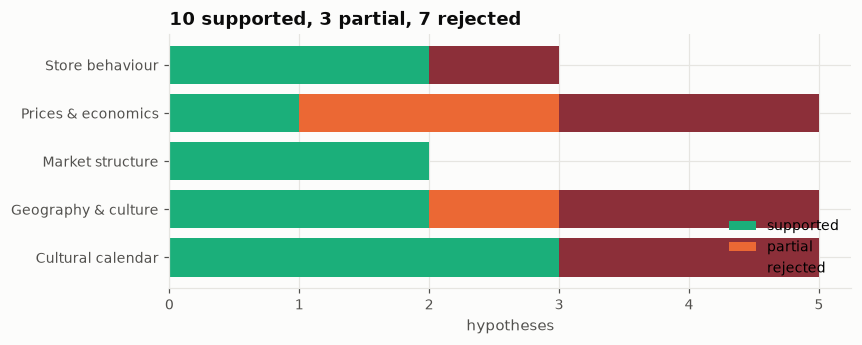

In [3]:
counts = results.groupby(["theme", "class"]).size().unstack(fill_value=0)[["supported", "partial", "rejected"]]
fig, ax = plt.subplots(figsize=(8, 3))
left = np.zeros(len(counts))
for cls, color in [("supported", P.AQUA), ("partial", P.ORANGE), ("rejected", "#8c2f39")]:
    ax.barh(counts.index, counts[cls], left=left, color=color, label=cls)
    left += counts[cls].values
ax.set_xlabel("hypotheses"); ax.legend(loc="lower right")
totals = results["class"].value_counts()
ax.set_title(f"{totals.get('supported', 0)} supported, {totals.get('partial', 0)} partial, {totals.get('rejected', 0)} rejected")
plt.show()

## 2. The statistics toolkit
Besides the regression toolkit of notebook 02 (OLS + HC3 + permutation), these tests use:

| Method | What it is, simply | Used in |
|---|---|---|
| **Moran's I** | Measures whether neighbouring counties have similar values (spatial autocorrelation). +1 = neighbours alike, 0 = random. Significance by shuffling values across the map. | H5 |
| **Hinge (piecewise) regression** | A line that rises up to a break point *k* and is flat after it; *k* is chosen by trying many values. Finds "how far does an effect reach?" | H6 |
| **Studentised residual** | How far a county sits from the regression's prediction, in standard errors. Beyond ±2 is unusual. | H7 |
| **Wilcoxon signed-rank test** | Compares two measurements *on the same units* (e.g. each store in March vs in summer) using ranks, so no normality assumption. | H8, H12, H20, H21 |
| **Placebo comparison** | Run the same test where no effect is expected (Scotch for St Patrick's Day). A real effect must beat it. | H8 |
| **Two-way fixed effects** | Regression that removes each item's own average and each month's statewide level, so only "unusual for this item in this month" remains. | H13 |
| **Mann–Whitney U test** | Compares two independent groups using ranks (are imports' price changes larger than domestic ones?). | H14, H22 |
| **Rarefaction** | Compare product variety fairly by drawing the **same number** of order lines from every county. Otherwise big counties look more varied just because they order more. | H18 |
| **Log-log (Zipf) regression** | Plot log(volume) against log(rank). A straight line with slope −1 is Zipf's law: the 2nd product sells half the 1st, the 3rd a third… | H19 |
| **Jensen–Shannon distance** | How different two mixes (e.g. two stores' shares of vodka, whiskey, …) are, from 0 (identical) to 1 (nothing in common). | H22 |
| **AUC (ROC)** | How well a score separates two groups: 0.5 = coin flip, 1.0 = perfect. | H21 |
| **Holm correction** | When running many tests, multiply the smallest p-value by 20, the next by 19, and so on. Controls the chance of *any* false positive. | all |

## 3. Geography & culture (H4–H7, H23)

In [4]:
def show(ids):
    return results[results.id.isin(ids)][["id", "hypothesis", "effect", "verdict"]].set_index("id")

show(["H4", "H5", "H6", "H7", "H23"])

,hypothesis,effect,verdict
id,,,
H4,Wisconsin's brandy culture crosses the Mississippi: brandy share rises the closer an Iowa county is to Wisconsin.,"WI-border counties 2.7% brandy vs 1.6% elsewhere (1.7x); Spearman(distance, share) = -0.31",SUPPORTED (both years)
H5,"Taste is contagious: after removing demographics, neighbouring counties still drink alike (spatially clustered resid...","2/8 families clustered in both years: whiskey I=0.142, rum I=0.167",SUPPORTED for 2/8 families
H6,"Border leakage has a travel-cost horizon: liters per adult rise with distance from Missouri, then flatten beyond a m...","break ~30 mi in 2026 (90% CI [30, 195]), 195 mi in 2025; +33.9% liters/adult per 10 mi inside the break",PARTIAL
H7,"Religion leaves a fingerprint: Dutch-Reformed Sioux County buys far less than its demographics, store count and bord...","Sioux buys -7% vs prediction (2026), rank 40/99 (2025 rank 44); studentised resid -0.23",NOT SUPPORTED
H23,"Iowa's whiskey divide is generational: within the whiskey aisle, Canadian whisky's share rises with a county's media...",Canadian is Iowa's #2 category overall; oldest-quintile counties 60% Canadian / 19% bourbon vs youngest 51% / 23%; w...,"REJECTED - age is only a proxy: rurality drives Canadian, education drives bourbon"


**H4 — the Wisconsin brandy belt.** Wisconsin is famous for brandy. Do Iowa counties on the Wisconsin border share the taste?

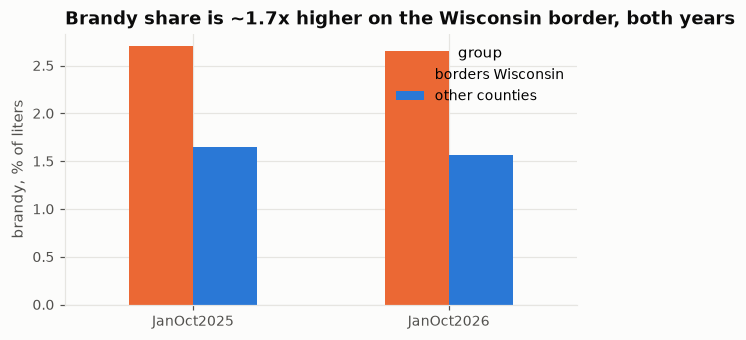

In [5]:
county = pd.read_parquet(C.PROCESSED / "county_period.parquet")
brandy = county[county.period.isin(["JanOct2025", "JanOct2026"])].copy()
brandy["group"] = np.where(brandy.geo_borders_wi == 1, "borders Wisconsin", "other counties")
brandy_share = 100 * brandy.groupby(["period", "group"]).brandy_share.mean().unstack()

ax = brandy_share.plot.bar(figsize=(6, 3.2), color=[P.ORANGE, P.BLUE], rot=0)
ax.set_xlabel(""); ax.set_ylabel("brandy, % of liters")
ax.set_title("Brandy share is ~1.7x higher on the Wisconsin border, both years")
plt.show()

**H5 — taste is contagious.** Moran's I of what demographics *cannot* explain, for each family:

In [6]:
moran = pd.DataFrame({family: {f"I {y}": v[y]["I"] for y in v} | {f"p {y}": v[y]["p"] for y in v}
                      for family, v in detail["H5"].items()}).T
moran

,I 2025,I 2026,p 2025,p 2026
vodka,0.170,0.088,0.0010,0.0615
whiskey,0.166,0.142,0.0025,0.0105
liqueur,0.012,0.071,0.3573,0.0835
rum,0.144,0.167,0.0090,0.0025
agave,0.017,-0.046,0.2979,0.7306
rtd,0.012,0.047,0.3373,0.1744
brandy,0.054,0.026,0.1294,0.2404
gin,-0.039,-0.002,0.6717,0.4213


Whiskey and rum cluster between neighbours in both years (p < 0.05): a regional taste that census data cannot predict.
Agave and gin do not: their geography is fully explained by demographics.

**H6 and H7.** The Missouri effect reaches about 30 miles in 2026 (but is linear in 2025, so *partial*). The
"Dutch-Reformed Sioux County is dry" story fails: Sioux ranks 40th of 99. The real outliers are:

In [7]:
pd.DataFrame(detail["H7"]["2026"]["bottom5"], columns=["county", "studentised residual (2026)"])

,county,studentised residual (2026)
0,Louisa,-2.61
1,Keokuk,-2.12
2,Audubon,-1.74
3,Tama,-1.48
4,Butler,-1.46


**H23 — the whiskey divide.** Within whiskey, older counties pour more Canadian whisky. But older counties are also
more rural. Which one drives it?

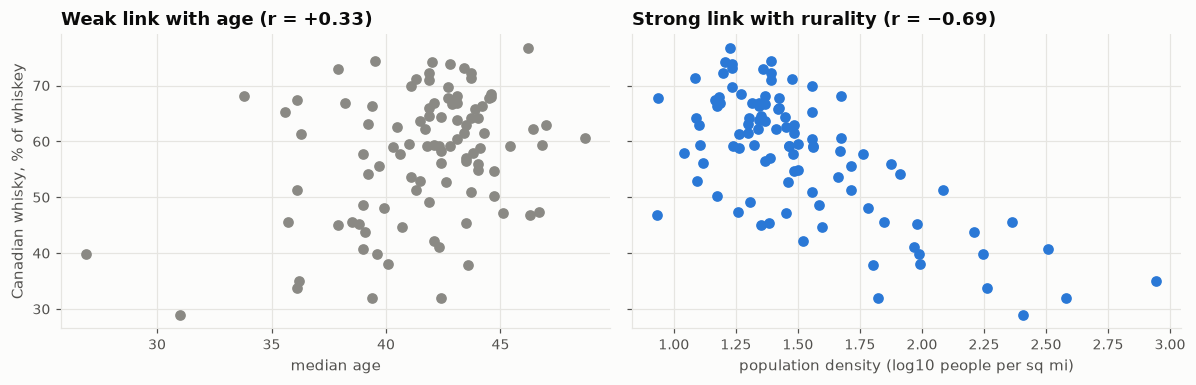

In [8]:
sales = pd.read_parquet(C.SSOT, columns=["month", "county_fips_code", "category_name", "family", "liters"])
for c in ["month", "county_fips_code", "category_name", "family"]:
    sales[c] = sales[c].astype(str)
sales_2026 = sales[(sales.month >= "2026-01") & (sales.month <= "2026-10")]
whiskey = sales_2026[sales_2026.family == "whiskey"]
canadian_share = (whiskey[whiskey.category_name == "CANADIAN WHISKIES"].groupby("county_fips_code").liters.sum()
                  / whiskey.groupby("county_fips_code").liters.sum())
profile = pd.read_parquet(C.COUNTY_PROFILE).set_index("county_fips_code")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
axes[0].scatter(profile.cty_median_age, 100 * canadian_share.reindex(profile.index), color=P.MUTED)
axes[0].set_xlabel("median age"); axes[0].set_ylabel("Canadian whisky, % of whiskey")
axes[0].set_title("Weak link with age (r = +0.33)")
axes[1].scatter(np.log10(profile.geo_pop_density), 100 * canadian_share.reindex(profile.index), color=P.BLUE)
axes[1].set_xlabel("population density (log10 people per sq mi)")
axes[1].set_title("Strong link with rurality (r = −0.69)")
plt.tight_layout(); plt.show()

**Verdict: rejected.** Once density and education are held fixed, the age effect reverses. Rurality drives Canadian
whisky; education drives bourbon. A textbook **confounder**: age looked important only because old counties are rural.

## 4. The cultural calendar (H8–H12)

In [9]:
show(["H8", "H9", "H10", "H11", "H12"])

,hypothesis,effect,verdict
id,,,
H8,"St Patrick's Day is visible in wholesale data: Irish whiskey's share jumps in Feb-Mar orders, while Scotch (same she...","Irish share +29% (2026), +24% (2025) vs Scotch +4%; peak month share 1.84% (2026-02) vs median 1.16%",SUPPORTED (both years; placebo flat)
H9,The Cinco de Mayo agave bump is bigger in counties with more Hispanic residents.,"statewide agave-share bump +16.2% (2026), +7.9% (2025); Hispanic slope +0.181 log-pts per +10 pts",REJECTED - bump exists but is no larger in Hispanic counties
H10,College towns empty out: Ames and Iowa City order far less in Jun-Jul relative to Sep-Oct than any normal county (st...,"2026: Story -37%, Johnson -25% vs median county; ranks 2 & 4/99",SUPPORTED (both years)
H11,The holiday gift economy is a rich-county thing: the Nov-Dec jump in premium share grows with county income.,"statewide premium share 24.8% -> 27.1%; +-0.00 pp per +$10k income; holiday mix: brandy +14%, liqueur +9%, rtd -33%",NOT SUPPORTED
H12,"Iowa rotates its palate with the seasons: RTD, rum, agave, gin and vodka gain share in summer; whiskey, liqueur and ...","rtd +48%, rum -3%, agave +9%, vodka +6%, liqueur -6%, brandy -7%, whiskey -6%, gin +14%",SUPPORTED for 7/8 predicted directions (fails: rum)


**H8 — St Patrick's Day.** Irish whiskey's share of liters by month, with Scotch as the placebo (same shelf, no holiday):

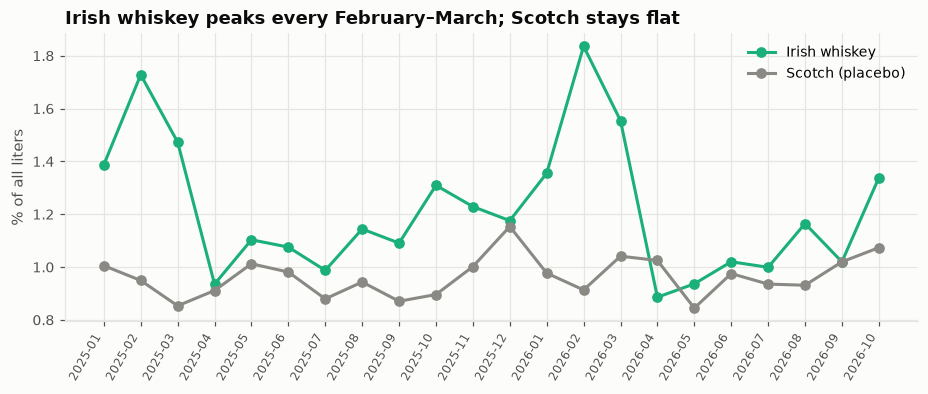

In [10]:
monthly_total = sales.groupby("month").liters.sum()
irish = sales[sales.category_name == "IRISH WHISKIES"].groupby("month").liters.sum() / monthly_total
scotch = sales[sales.category_name.isin(["SCOTCH WHISKIES", "SINGLE MALT SCOTCH"])].groupby("month").liters.sum() / monthly_total

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(irish.index, 100 * irish, marker="o", color=P.AQUA, label="Irish whiskey")
ax.plot(scotch.index, 100 * scotch, marker="o", color=P.MUTED, label="Scotch (placebo)")
ax.set_ylabel("% of all liters"); ax.legend()
ax.set_title("Irish whiskey peaks every February–March; Scotch stays flat")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right", fontsize=8)
plt.show()

The peak lands in **February**: stores restock 3–6 weeks before March 17. Plan Irish whiskey in January.

**H10 — college towns empty out.** For each county: summer (Jun+Jul) liters relative to autumn (Sep+Oct), 2026.

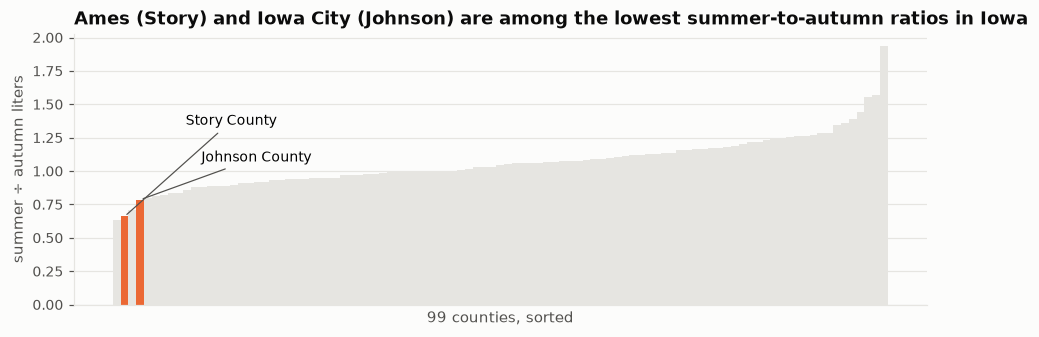

lowest of all: Humboldt County (0.63)


In [11]:
county_month = sales.groupby(["county_fips_code", "month"]).liters.sum().unstack()
summer_vs_fall = (county_month["2026-06"] + county_month["2026-07"]) / (county_month["2026-09"] + county_month["2026-10"])
summer_vs_fall = summer_vs_fall.sort_values()
names = profile.county_name.reindex(summer_vs_fall.index)
colors = [P.ORANGE if n in ("Story", "Johnson") else P.GRID for n in names]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(summer_vs_fall)), summer_vs_fall.values, color=colors, width=1.0)
offsets = iter([(40, 60), (40, 25)])
for i, n in enumerate(names):
    if n in ("Story", "Johnson"):
        ax.annotate(f"{n} County", (i, summer_vs_fall.iloc[i]), xytext=next(offsets), textcoords="offset points",
                    fontsize=9, arrowprops=dict(arrowstyle="-", color=P.INK2, lw=0.8))
ax.set_xticks([]); ax.set_xlabel("99 counties, sorted"); ax.set_ylabel("summer ÷ autumn liters")
ax.set_title("Ames (Story) and Iowa City (Johnson) are among the lowest summer-to-autumn ratios in Iowa")
plt.show()
print(f"lowest of all: {names.iloc[0]} County ({summer_vs_fall.iloc[0]:.2f})")

Story and Johnson are 2nd and 4th lowest of 99 in 2026 (2nd and 14th in 2025).
Students leave in summer and come back for autumn (and football). Census data cannot see this; a term-calendar feature can.

**H12 — the palate rotates with the seasons.** Store-level change in each family's share, summer vs winter:

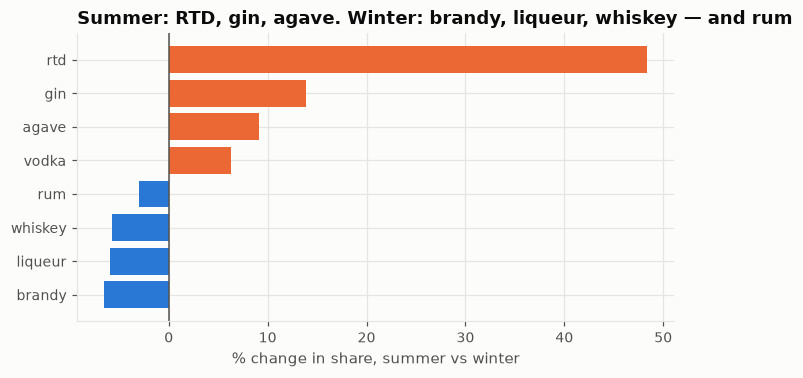

In [12]:
seasons = pd.Series({f: v["summer_vs_winter"] for f, v in detail["H12"].items()}).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(seasons.index, 100 * seasons.values, color=[P.ORANGE if v > 0 else P.BLUE for v in seasons])
ax.axvline(0, color=P.INK2, lw=1)
ax.set_xlabel("% change in share, summer vs winter")
ax.set_title("Summer: RTD, gin, agave. Winter: brandy, liqueur, whiskey — and rum")
plt.show()

Seven of eight directions were predicted correctly. The surprise: **rum is a winter spirit in Iowa** (spiced rum,
holiday punches), not a beach drink. **H9:** the Cinco de Mayo agave bump is real (+16% in 2026) but no bigger in
Hispanic counties: a statewide party occasion. **H11:** holiday trading-up happens at every income level.

## 5. Prices & economics (H13–H17)

In [13]:
show(["H13", "H14", "H15", "H16", "H17"])

,hypothesis,effect,verdict
id,,,
H13,State price cuts mostly move orders in time: retailers stock up during a temporary cost cut and then under-order onc...,"orders +14% in promo months (median cut 12%, implied arc elasticity -1.0); +49% the month after; +1% the month before","REJECTED - timing is reversed: the surge comes the month AFTER the cut (p=7.3e-08), no hangover"
H14,The 2025-26 tariff era shows up on the shelf: same-item wholesale costs rose more for imported spirits than for Amer...,Canada -0.2% (n=111); Mexico -0.6% (n=345); Other import +0.5% (n=375); UK/Ireland -0.7% (n=173); USA -1.1% (n=1259),NOT SUPPORTED
H15,Inequality builds a barbell: high-Gini counties buy a wider spread of price tiers (more bottom shelf AND more top sh...,"SD: +0.0038 per Gini point (2026), +0.0036 (2025); mean price: +0.0081 (SUPPORTED (both years); not under pop. weights)","PARTIAL - spread widens, but the average price rises too (both years); not under pop. weights"
H16,"The 50 ml 'nip' is a poverty index: poorer counties spend a larger share on mini bottles, even comparing stores of t...","+-0.13% mini share per +10 pts poverty (county, 2026); store-level within type +3.30% (p=0.019)","PARTIAL - holds within store type (store level), not across counties"
H17,"More outlets, more drinking - but only partly: liters per adult rise with store density with an elasticity well belo...","elasticity 0.76 (2026), 0.59 (2025); H3-implied 0.40",SUPPORTED (both years)


**H13 — do price cuts make stores stock up?** We expected *forward buying*: orders jump during a temporary cost cut,
then dip after. Item × month fixed effects on 2,251 regularly stocked products:

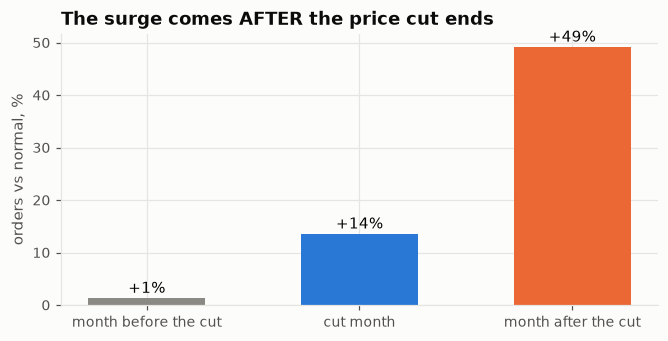

In [14]:
effects = detail["H13"]["params"]
labels = ["month before the cut", "cut month", "month after the cut"]
values = [np.expm1(effects["before"]), np.expm1(effects["promo"]), np.expm1(effects["after"])]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(labels, [100 * v for v in values], color=[P.MUTED, P.BLUE, P.ORANGE], width=0.55)
for i, v in enumerate(values):
    ax.text(i, 100 * v + 1, f"{100 * v:+.0f}%", ha="center")
ax.set_ylabel("orders vs normal, %"); ax.set_title("The surge comes AFTER the price cut ends")
plt.show()

**Rejected — and the reverse is true.** Orders barely move during the cut and jump ~49% the month after. Likely
mechanism: stores pass the cut on to shoppers, sell through, then restock at full price. Planning lesson: promotion
stock is needed in month *t+1*.

*Data-quality note:* the wholesale cost is blank for Jan–Jun 2025 and truncated to whole dollars in Nov 2025–Jan 2026
(which would look like ~900 fake price cuts), so this test uses only clean-price months.

**H14 — tariffs.** Same-product cost change, Jul–Oct 2026 vs 2025, by country of origin:

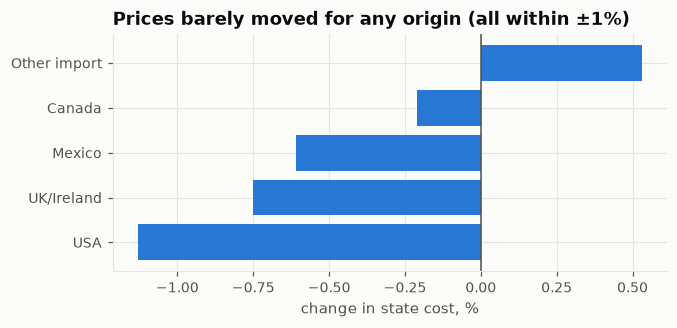

In [15]:
tariff = pd.Series(detail["H14"]["wmean_pct"]).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(tariff.index, 100 * tariff.values, color=P.BLUE)
ax.axvline(0, color=P.INK2, lw=1)
ax.set_xlabel("change in state cost, %"); ax.set_title("Prices barely moved for any origin (all within ±1%)")
plt.show()

**H17 — more outlets, more drinking?** Counties with more stores per adult buy more per adult, but less than one-for-one:

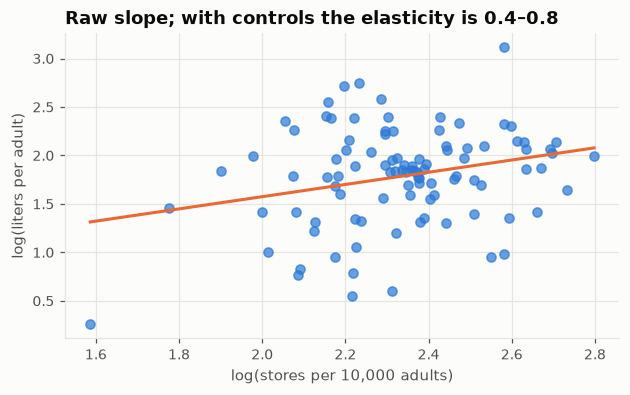

In [16]:
c26 = county[county.period == "JanOct2026"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(np.log(c26.stores_per_10k_adults), c26.log_liters_per_adult, color=P.BLUE, alpha=0.7)
slope, intercept = np.polyfit(np.log(c26.stores_per_10k_adults), c26.log_liters_per_adult, 1)
xs = np.linspace(np.log(c26.stores_per_10k_adults).min(), np.log(c26.stores_per_10k_adults).max(), 10)
ax.plot(xs, intercept + slope * xs, color=P.ORANGE)
ax.set_xlabel("log(stores per 10,000 adults)"); ax.set_ylabel("log(liters per adult)")
ax.set_title("Raw slope; with controls the elasticity is 0.4–0.8")
plt.show()

An elasticity of ~0.4–0.5 (population-weighted) means: double the outlets, and liters per adult rise ~40–50%, not
100%. That matches H3 from a completely different method: if ~60% of a new store's volume is stolen from neighbours,
~40% is new. **Two independent methods, one answer.**

## 6. Market structure & store behaviour (H18–H22)

In [17]:
show(["H18", "H19", "H20", "H21", "H22"])

,hypothesis,effect,verdict
id,,,
H18,"The long tail lives in cities: for the same number of order lines, dense counties buy many more distinct products an...",+75 distinct SKUs per log-unit of density; densest decile 547 vs sparsest 322 SKUs; vendor HHI slope +0.0019,SUPPORTED
H19,"Spirits obey Zipf's law: product volume falls as 1/rank, so a tiny head of SKUs carries the state and the head is st...","slope -1.10 (95% CI -1.11 to -1.09; Zipf = -1); top 1% of 4,792 SKUs = 38% of liters, top 20% = 91%; top-100 stabili...",SUPPORTED (Zipf-like)
H20,New stores have a honeymoon: the opening order (empty shelves being filled) overshoots the store's steady-state mont...,"median ratio by month since opening: m0=1.86, m1=0.79, m2=0.89, m3=0.94, m4=0.95, m5=0.98, m6=0.98 (n=191)",SUPPORTED - and followed by a dip below steady state in month 1
H21,"Stores die slowly, not suddenly: in the 3 months before their last order, exiting stores' volume and product range s...","median volume -6%, median SKU range -5% before exit; early-warning AUC = 0.53",MOSTLY REJECTED - the decline is small and useless as a warning: stores die suddenly
H22,"Customers belong to the address, not the owner: when a shop changes hands, the new licensee's product mix is far clo...",median JS distance 0.123 at same address vs 0.254 random same-type (49% of it); successor's monthly volume = 92% of ...,SUPPORTED


**H19 — Zipf's law.** Each product's 2026 volume against its rank, on log-log axes:

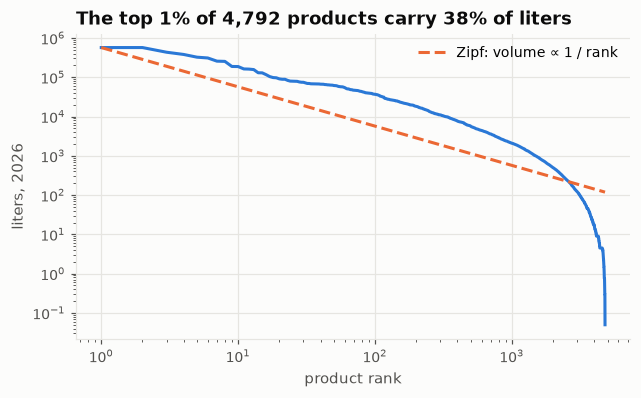

In [18]:
items = pd.read_parquet(C.SSOT, columns=["month", "item_no", "liters"])
items["month"] = items.month.astype(str)
item_volume = items[(items.month >= "2026-01") & (items.liters > 0)].groupby("item_no").liters.sum().sort_values(ascending=False)
rank = np.arange(1, len(item_volume) + 1)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.loglog(rank, item_volume.values, color=P.BLUE)
ax.loglog(rank, item_volume.values[0] / rank, color=P.ORANGE, ls="--", label="Zipf: volume ∝ 1 / rank")
ax.set_xlabel("product rank"); ax.set_ylabel("liters, 2026"); ax.legend()
top1 = item_volume.head(int(np.ceil(0.01 * len(item_volume)))).sum() / item_volume.sum()
ax.set_title(f"The top 1% of {len(item_volume):,} products carry {100 * top1:.0f}% of liters")
plt.show()
del items

The middle of the curve (ranks 10–1,000) is close to a straight line with slope −1.10, near Zipf's −1; the
flat head and the steep tail (rarely ordered products) bend away from it. The top 100 products barely change between
years (rank correlation 0.93): forecast those individually, and treat the tail as a group.

**H20 — the new-store honeymoon.** A new store's monthly liters relative to its own steady state (months 3–5):

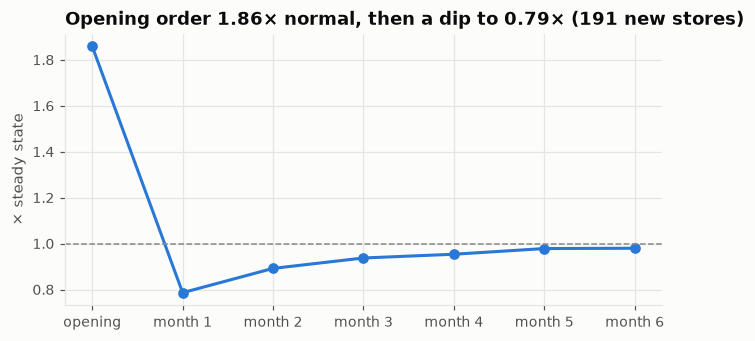

In [19]:
ratio = pd.Series({int(k): v for k, v in detail["H20"]["median_ratio"].items()}).sort_index()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ratio.index, ratio.values, marker="o", color=P.BLUE)
ax.axhline(1, color=P.MUTED, ls="--", lw=1)
ax.set_xticks(ratio.index, ["opening"] + [f"month {k}" for k in ratio.index[1:]])
ax.set_ylabel("× steady state")
ax.set_title(f"Opening order {ratio[0]:.2f}× normal, then a dip to {ratio[1]:.2f}× ({detail['H20']['n']} new stores)")
plt.show()

Shelves are filled at opening, then the store works through that stock. A forecast built on the opening order
overshoots month 1 by ~2.4×; plan entrants from similar stores until month 3.

**H21 — do dying stores fade slowly?** No. In their last three months exiting stores are only ~6% below normal, and as
an early-warning score the decline has **AUC 0.53**, a coin flip. Stores close suddenly (sale, licence loss), so ABD
cannot see exits coming in order data.

**H22 — customers belong to the address.** When a shop changes owner, the new owner's family mix is half as far from
the old one's as from a random store of the same type (Jensen–Shannon 0.12 vs 0.25), and keeps ~92% of the volume.
An ownership change is not a new store: forecast it from its predecessor's history.

**H18 — the long tail lives in cities.** For the same number of order lines, the densest counties buy ~547 distinct
products against ~322 in the sparsest.

## 7. Caveats (say these out loud)
* **Exploratory, not pre-registered.** Six results survive the Holm correction (H6, H12, H18, H20, H21, H22). H4, H8, H10
  and H17 do not survive it alone, but each **replicates in two independent years**, which is the stronger test.
* **Orders ≠ consumption.** Every calendar effect is a *restocking* effect, weeks ahead of the occasion.
* **Associations, not causes**, except where the design gives leverage (the placebo in H8, fixed effects in H13,
  rarefaction in H18).
* Thresholds (5% price cut, equal-size rarefaction samples, 3-month windows) were fixed before seeing results;
  sensitivity to them is not reported.

Full write-up: `reports/twenty_hypotheses.md`. Slides 14–19 of the final presentation.